<h3>Transforming algorithm - optimizations attempts for regression - case diamonds data</h3>

**Lock down the randomness first (for reproducability of results):**

In [23]:
import os
import random
import numpy as np

# seed = 153262
seed = 1995
os.environ['PYTHONHASHSEED'] = str(seed)      
random.seed(seed)                             
np.random.seed(seed)

<b>Imports + load data, drop some columns</b>

In [24]:
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor

# 1. Load diamonds dataset
diamonds = sns.load_dataset('diamonds')

# these are actually ordinal categories when it comes to diamond color and clarity
# since this is a well known dataset, this preprocessing step was generated with AI
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']

color_order = ['J', 'I', 'H', 'G', 'F', 'E', 'D']

clarity_order = ['I1', 'SI2', 'SI1', 'VS2',
                 'VS1', 'VVS2', 'VVS1', 'IF']

# 3. Convert ordinal variables into ordered categorical types
diamonds['cut'] = pd.Categorical(
    diamonds['cut'],
    categories=cut_order,
    ordered=True
)

diamonds['color'] = pd.Categorical(
    diamonds['color'],
    categories=color_order,
    ordered=True
)

diamonds['clarity'] = pd.Categorical(
    diamonds['clarity'],
    categories=clarity_order,
    ordered=True
)

# 4. Convert ordinal categories to numerical ranks
for col in ['cut', 'color', 'clarity']:
    diamonds[col] = diamonds[col].cat.codes

# let's use df as the dataframe name for later usages
df = diamonds

# convert to booleans to int
bool_cols = df.select_dtypes(include=['bool']).columns
df[bool_cols] = df[bool_cols].astype(int)
df


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4,5,1,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,5,2,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,5,4,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3,1,3,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1,0,1,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,4,6,2,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,1,6,2,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,2,6,2,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,3,2,1,61.0,58.0,2757,6.15,6.12,3.74


**There's ~54000 diamonds in the dataset.**

**It's possible the preprocess this further, e.g. remove outliers etc. if needed**

Uncomment the code below in order to remove some outliers.

In [25]:
# # we'll aim to get this closer to a normal distribution
# # current distribution is right-skewed heavily

# # removing some outliers first to make it easier to undesrample in the future
# # can process the whole dataset 
# # and compares variables to each other instead
# # of focusing on outliers on a single variable
# from sklearn.ensemble import IsolationForest

# # adjust the contamination rate as you see fit
# # for example, if you expect 5% of the data to be outliers
# # you can use 0.05 etc. 
# iso = IsolationForest(contamination=0.02) 

# # fit isolation forest
# y_pred = iso.fit_predict(df)

# # filter outliers only
# outliers = df[y_pred != 1]
# df = df.drop(outliers.index)

<Axes: xlabel='price', ylabel='Count'>

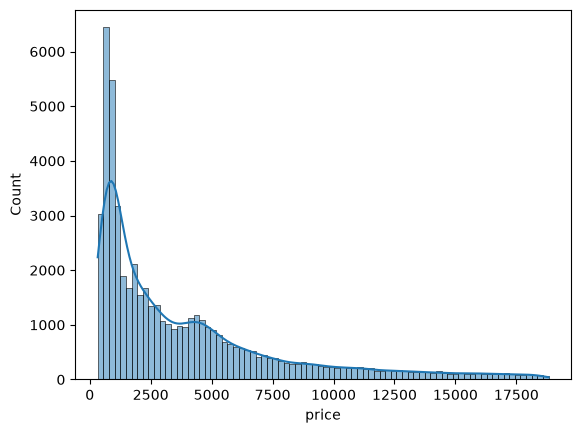

In [26]:
# histogram to see the distribution of target variable
sns.histplot(data=df, x="price", kde=True)

**Let's make our BASELINE model without any transformation algorithms**

In [27]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
import sklearn.metrics as metrics
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

import seaborn as sns
import xgboost as xgb


In [28]:
# X/y 
X = df.drop("price", axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# model1 = xgb.XGBRegressor(objective='reg:squarederror')
#model1 = LinearRegression()
model1 = MLPRegressor()
model1.fit(X_train, y_train)
predictions = model1.predict(X_test)

# RMSE - Root mean square error
print('\nRMSE:')
print(round(np.sqrt(metrics.mean_squared_error(y_test, predictions)), 2), "$")

# R-squared. 0 = the model descibes the dataset poorly
# 1 = model describes the dataset perfectly
print('\nR-squared:')
print(round(metrics.r2_score(y_test, predictions), 2))



RMSE:
1186.32 $

R-squared:
0.91


c:\Users\tuomas.valtanen\dataeng_advda2026_lectures\DataEngineering_AdvDA_2026\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [29]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4,5,1,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,5,2,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,5,4,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3,1,3,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1,0,1,63.3,58.0,335,4.34,4.35,2.75


**Experiment 1: RobustScaler + Yeo-Johson (transformation)**

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, PowerTransformer, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Split features and target
X = df.drop("price", axis=1)
y = df['price'].values.reshape(-1, 1)  # reshape needed for PowerTransformer

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scale features
x_scaler = RobustScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# 4. Initialize PowerTransformer with Yeo-Johnson
y_transformer = PowerTransformer(method='yeo-johnson', standardize=False)
y_train_trans = y_transformer.fit_transform(y_train)

# 5. Transform test target (optional, just for reference)
y_test_trans = y_transformer.transform(y_test)

# 6. Train model on transformed target
model = MLPRegressor()
model.fit(X_train_scaled, y_train_trans.ravel())

# 7. Predict on test set (transformed space)
predictions_trans = model.predict(X_test_scaled)

# 8. Inverse transform predictions back to original scale
predictions = y_transformer.inverse_transform(predictions_trans.reshape(-1, 1)).ravel()

# 9. Evaluate on original scale
rmse = np.sqrt(metrics.mean_squared_error(y_test.ravel(), predictions))
r2 = metrics.r2_score(y_test.ravel(), predictions)

print('\nRMSE:')
print(round(rmse, 2), "$")

print('\nR-squared:')
print(round(r2, 2))

# it seems, R-squared => +5% 
# RMSE dropped ~ 360 USD $



RMSE:
825.58 $

R-squared:
0.96


**Experiment 2: MinMaxScaler + Yeo-Johson (transformation)**

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, PowerTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Split features and target
X = df.drop("price", axis=1)
y = df['price'].values.reshape(-1, 1)  # reshape needed for PowerTransformer

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Scale features
x_scaler = MinMaxScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# 4. Initialize PowerTransformer with Yeo-Johnson
y_transformer = PowerTransformer(method='yeo-johnson', standardize=False)
y_train_trans = y_transformer.fit_transform(y_train)

# 5. Transform test target (optional, just for reference)
y_test_trans = y_transformer.transform(y_test)

# 6. Train model on transformed target
model = MLPRegressor()
model.fit(X_train_scaled, y_train_trans.ravel())

# 7. Predict on test set (transformed space)
predictions_trans = model.predict(X_test_scaled)

# 8. Inverse transform predictions back to original scale
predictions = y_transformer.inverse_transform(predictions_trans.reshape(-1, 1)).ravel()

# 9. Evaluate on original scale
rmse = np.sqrt(metrics.mean_squared_error(y_test.ravel(), predictions))
r2 = metrics.r2_score(y_test.ravel(), predictions)

print('\nRMSE:')
print(round(rmse, 2), "$")

print('\nR-squared:')
print(round(r2, 2))

# it seems, R-squared => +5% 
# RMSE dropped ~ 410 USD $


RMSE:
775.08 $

R-squared:
0.96


**Experiment 3: MinMaxScaler + QuantileTransformer**

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler, QuantileTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn import metrics

# 1. Split features and target
X = df.drop("price", axis=1)
y = df['price'].values.reshape(-1, 1)

# 2. Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Scale features
x_scaler = MinMaxScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# 4. Initialize QuantileTransformer
y_transformer = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=min(1000, len(y_train)),
    random_state=42
)

y_train_trans = y_transformer.fit_transform(y_train)

# 5. Transform test target
y_test_trans = y_transformer.transform(y_test)

# 6. Train model on transformed target
model = MLPRegressor()
model.fit(X_train_scaled, y_train_trans.ravel())

# 7. Predict on test set
predictions_trans = model.predict(X_test_scaled)

# 8. Inverse transform predictions
predictions = y_transformer.inverse_transform(
    predictions_trans.reshape(-1, 1)
).ravel()

# 9. Evaluate on original scale
rmse = np.sqrt(metrics.mean_squared_error(y_test.ravel(), predictions))
r2 = metrics.r2_score(y_test.ravel(), predictions)

print('\nRMSE:')
print(round(rmse, 2), "$")

print('\nR-squared:')
print(round(r2, 2))

# this is currently the best one
# R-squared => +0.06
# RMSE dropped ~ 540 USD $


RMSE:
641.56 $

R-squared:
0.97


In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from scipy.stats import boxcox
from scipy.special import inv_boxcox

X = df.drop("price", axis=1)
y = df['price']

# Check for non-positive targets
if (y <= 0).any():
    raise ValueError("Box-Cox requires strictly positive target values.")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

x_scaler = MinMaxScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)

# Box-Cox transform only training target
y_train_bc, fitted_lambda = boxcox(y_train)

model = MLPRegressor()
model.fit(X_train_scaled, y_train_bc)

# Predict in transformed space
predictions_bc = model.predict(X_test_scaled)

# Inverse transform predictions back to original scale
predictions = inv_boxcox(predictions_bc, fitted_lambda)

# Calculate metrics on original target scale (no need to transform y_test)
rmse = np.sqrt(metrics.mean_squared_error(y_test, predictions))
r2 = metrics.r2_score(y_test, predictions)

print('\nRMSE:')
print(round(rmse, 2), "$")

print('\nR-squared:')
print(round(r2, 2))

# pretty good results, not as good as Quantile previously, unfortunately


RMSE:
714.72 $

R-squared:
0.97


**Experiment 4: Log transform**

In [34]:
import numpy as np

# Log-transform the target
y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

# Train model on log-transformed target
model = MLPRegressor()
model.fit(X_train_scaled, y_train_log)

# Predict on test set (log space)
predictions_log = model.predict(X_test_scaled)

# Inverse transform predictions back to original scale
predictions = np.exp(predictions_log)

# Evaluate on original scale
rmse = np.sqrt(metrics.mean_squared_error(y_test, predictions))
r2 = metrics.r2_score(y_test, predictions)

print('\nRMSE (log transform):')
print(round(rmse, 2), "$")

print('\nR-squared (log transform):')
print(round(r2, 2))



RMSE (log transform):
746.63 $

R-squared (log transform):
0.96


In [ ]:
# QuantileTransfomer + MinMaxScaler got the best result so far:

# R-squared => +0.06
# RMSE dropped ~ 540 USD $

# typically regression datasets that don't have a natural standard normal distribution
# in the target variable => these usually benefit from transformation algorithms

# which transformation algorithm + scaler is the best combo?
# => you need to experiment / trial & error

In [ ]:
# ML MODELS/ALGORITHMS THAT USUALLY BENEFIT FROM TRANSFORMATION ALGORITHMS:

# Linear Regression, 
# Ridge Regression, 
# KNN, 
# SVR, 
# Logistic regression, 
# Neural networks (MLPRegressor is based on neural networks)

# many surprising models don't really benefit from them:
# decision trees / random forest
# gradient boosting, XGBoost, LightGBM, CatBoost...
# => so technically => ensemble methods don't really benefit from this